# S05b: S05a with measured transaction costs

Pre-registration: [`S05b_README.md`](S05b_README.md). Strategy unchanged from S05a; only the cost model changes.

1. Sample NBBO quotes (Alpaca SIP) in the first 3 seconds after every 15m bar start, on 4 calendar-random sessions per year, for every stock and sector ETF.
2. Cost model: per symbol-year median half-spread × an intraday profile.
3. Re-run the S05a backtest, placebos and gates with those costs.

In [1]:
N_PLACEBO = 200            # gates are defined for 1000
N_JOBS = -1
PER_YEAR = 4                 # sampled sessions per year (pre-registered)
WINDOW_S = 3.0               # seconds after each bar start
QUOTE_WORKERS = 4            # parallel sessions (one shared rate limit)

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("S05_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s05.S05Config(n_placebo=N_PLACEBO)
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 20

tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s05{s05.S05_VERSION}_s05b{s05b.S05B_VERSION}"
OUT = ROOT / "results" / ("s05b_synthetic" if SYNTHETIC else "s05b")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s05b" / tag
CACHE.mkdir(parents=True, exist_ok=True)
PANEL_CACHE = work_dir() / "results" / "s05a" / (("synthetic_" if SYNTHETIC else "") + f"panel_{CFG.timeframe}_alpaca{ALPACA_VERSION}.npz")
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"{CFG.timeframe}_w{WINDOW_S:g}s"
QUOTE_CACHE.mkdir(parents=True, exist_ok=True)

COL = {"strategy": "#2a78d6", "timing": "#1baf7a", "cost2": "#eb6834", "grey": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})

if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    BENCH = "XLK"
else:
    constituents = pd.read_csv(ROOT / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH = "SPY"
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | stocks={len(STOCKS)} | placebos={N_PLACEBO} | quote cache={QUOTE_CACHE}")

synthetic=False | stocks=503 | placebos=200 | quote cache=D:\MarketData\Alpaca\quote_samples\15Min_w3s


## 1. Data (the S05a panel)

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
elif PANEL_CACHE.exists():
    z = np.load(PANEL_CACHE, allow_pickle=True)
    panel = s04.Panel(index=pd.DatetimeIndex(z["index"]).tz_localize("UTC").tz_convert(s04.NY), symbols=list(z["symbols"]),
                      o=z["o"], c=z["c"], day_start=z["day_start"], days=z["days"], s2_daily=z["s2"])
else:
    download_years(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, workers=8)
    panel = s04.load_panel(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)
    np.savez(PANEL_CACHE, index=panel.index.tz_convert("UTC").tz_localize(None).to_numpy(), symbols=np.array(panel.symbols),
             o=panel.o, c=panel.c, day_start=panel.day_start, days=panel.days, s2=panel.s2_daily)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
print(f"panel {panel.c.shape} in {time.time() - t0:.0f}s | traded stocks {len(TRADED)} | symbols to quote {len(QUOTED)}")

panel (39064, 513) in 2s | traded stocks 501 | symbols to quote 512


## 2. Quote sampling (Alpaca SIP NBBO)

Sessions are drawn from the exchange calendar with a fixed seed; no price data is used to choose them. Each session is cached once complete, so an interrupted run resumes.

In [3]:
SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=CFG.seed)
print("sampled sessions:", [str(d) for d in SESSIONS])
t0 = time.time()
if SYNTHETIC:                                        # synthetic panel has a known 3 bps half-spread
    samples = pd.DataFrame([(s, 3e-4 * (1.5 if k == 0 else 1.0), 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    from concurrent.futures import ThreadPoolExecutor
    def one(d):
        return sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    todo = [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]
    print(f"{len(SESSIONS) - len(todo)} sessions cached, {len(todo)} to fetch "
          f"(~{len(todo) * 26 * int(np.ceil(len(QUOTED) / 100))} requests minimum)", flush=True)
    with ThreadPoolExecutor(QUOTE_WORKERS) as ex:
        for k, df in enumerate(ex.map(one, SESSIONS)):
            print(f"  session {k + 1}/{len(SESSIONS)} done, {(time.time() - t0) / 60:.1f} min", flush=True)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
samples.to_csv(OUT / "quote_samples.csv.gz", index=False, float_format="%.6g")
cov = samples.assign(ok=samples.half_spread.notna())
print(f"samples {len(samples):,} | with a valid quote {cov.ok.mean():.1%} | quotes per sample median {samples.n_quotes.median():.0f}")

sampled sessions: ['2020-02-04', '2020-06-11', '2020-08-26', '2020-10-08', '2021-02-05', '2021-03-17', '2021-07-14', '2021-09-10', '2022-02-17', '2022-07-08', '2022-09-16', '2022-10-12', '2023-03-09', '2023-05-15', '2023-10-12', '2023-12-01', '2024-03-25', '2024-06-10', '2024-06-13', '2024-07-17', '2025-01-27', '2025-04-14', '2025-10-29', '2025-11-06']
15 sessions cached, 9 to fetch (~1404 requests minimum)
  session 1/24 done, 0.0 min
  session 2/24 done, 0.0 min
  session 3/24 done, 0.0 min
  session 4/24 done, 0.0 min
  session 5/24 done, 0.1 min
  session 6/24 done, 0.1 min
  session 7/24 done, 0.1 min
  session 8/24 done, 0.1 min
  session 9/24 done, 0.1 min
  session 10/24 done, 0.1 min
  session 11/24 done, 0.1 min
  session 12/24 done, 0.1 min
  session 13/24 done, 0.1 min
  session 14/24 done, 0.1 min
  session 15/24 done, 0.1 min
  session 16/24 done, 16.3 min
  session 17/24 done, 16.3 min
  session 18/24 done, 16.3 min
  session 19/24 done, 16.3 min
  session 20/24 done, 27

## 3. Cost model

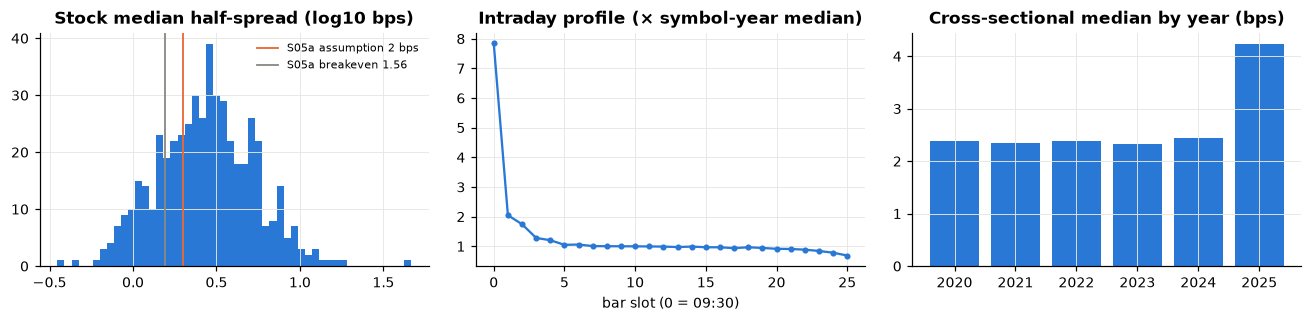

,stocks_median_bps,stocks_p90_bps,etfs_median_bps
year,,,
2020,2.683,5.617,0.834
2021,2.636,6.080,0.656
2022,2.653,6.191,0.700
2023,2.573,5.923,0.635
2024,2.732,6.645,0.557
2025,4.940,10.570,0.566


cost array (39064, 513), traded-stock bar median 3.01 bps, ETF median 0.65 bps


In [4]:
M = s05b.cost_model(samples)
base_bps = M["base"] * 1e4
stock_base = base_bps.reindex([s for s in TRADED if s in base_bps.index])
etf_base = base_bps.reindex([e for e in ETFS if e in base_bps.index])
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(np.log10(stock_base.median(axis=1).clip(lower=0.05)), bins=50, color=COL["strategy"])
for v, lab in ((CFG.half_spread_bps, "S05a assumption 2 bps"), (1.56, "S05a breakeven 1.56")):
    ax[0].axvline(np.log10(v), color=COL["cost2"] if v == 2 else COL["grey"], lw=1.2, label=lab)
ax[0].set_title("Stock median half-spread (log10 bps)"); ax[0].legend(frameon=False, fontsize=7)
ax[1].plot(M["profile"].index, M["profile"].values, marker="o", ms=3, color=COL["strategy"]); ax[1].set_title("Intraday profile (× symbol-year median)")
ax[1].set_xlabel("bar slot (0 = 09:30)")
ax[2].bar(M["year_median"].index.astype(str), M["year_median"].values * 1e4, color=COL["strategy"]); ax[2].set_title("Cross-sectional median by year (bps)")
plt.tight_layout(); plt.show()
cost_table = pd.DataFrame({"stocks_median_bps": stock_base.median(), "stocks_p90_bps": stock_base.quantile(0.9),
                           "etfs_median_bps": etf_base.median()})
display(cost_table.round(3))
base_bps.to_csv(OUT / "cost_base_bps_symbol_year.csv", float_format="%.4f")
M["profile"].rename("ratio").to_csv(OUT / "cost_profile_slot.csv", float_format="%.4f")
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, M)
print(f"cost array {H.shape}, traded-stock bar median {np.median(H[:, SC]) * 1e4:.2f} bps, ETF median {np.median(H[:, np.unique(EC)]) * 1e4:.2f} bps")

## 4. Strategy backtest with measured costs (1×, 2×, 0×)

estimated in 30s
3 backtests in 21s; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days
1x cost,-0.3456,-1.1436,0.3488,-0.0003,1486.0
2x cost,-0.6589,-3.0595,0.6569,-0.0007,1486.0
0x cost,0.3785,0.9268,0.1050,0.0002,1486.0


,"strategy, measured costs"
trades,60598.0000
mean_gross_bps,5.7360
cost_per_trade_bps,12.7461
gross_pnl,22520.0195
total_cost,57081.3887
breakeven_cost_multiple,0.3945
avg_open_positions,99.6550


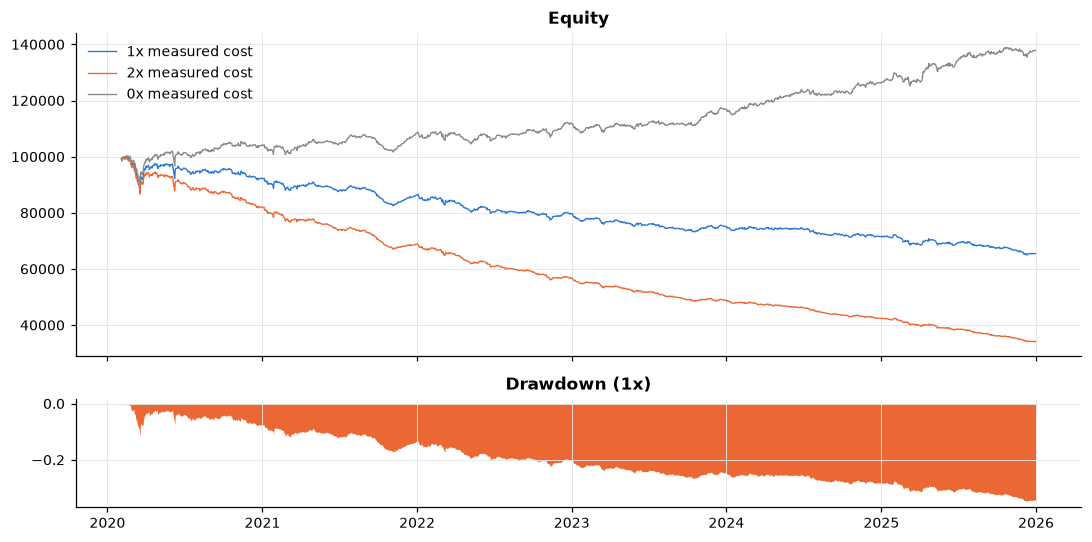

,2020,2021,2022,2023,2024,2025
net return by year,-0.0772,-0.0635,-0.077,-0.0575,-0.049,-0.0847


In [5]:
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    t0 = time.time(); P = s05.estimate_all(panel, SC, EC, CFG, s05.first_decision_day(CFG))
    np.savez(est_path, **P); print(f"estimated in {time.time() - t0:.0f}s")
t0 = time.time()
runs = {m: s05.backtest(panel, P, SC, EC, replace(CFG, cost_mult=m), record=(m == 1.0), half_spread=H) for m in (1.0, 2.0, 0.0)}
base = runs[1.0]
START = base["first_day"]
print(f"3 backtests in {time.time() - t0:.0f}s; trading starts {START.date()}")
metrics = pd.DataFrame({f"{m:g}x cost": s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START) for m, r in runs.items()})
display(metrics.T.round(4))
trades = base["trades"].copy()
trades["symbol"] = [TRADED[i] for i in trades["i"]]
gross_total = float(trades.gross_pnl.sum())
tstats = {"trades": int(len(trades)), "mean_gross_bps": float(1e4 * trades.gross_ret.mean()),
          "cost_per_trade_bps": float(1e4 * base["total_cost"] / trades.notional.sum()),
          "gross_pnl": gross_total, "total_cost": float(base["total_cost"]),
          "breakeven_cost_multiple": float(gross_total / base["total_cost"]) if base["total_cost"] > 0 else np.inf,
          "avg_open_positions": float(base["n_open"][panel.day_start[s05.first_decision_day(CFG) + 1]:].mean())}
display(pd.Series(tstats).round(4).to_frame("strategy, measured costs"))
trades.drop(columns=["i"]).to_csv(OUT / "trades.csv", index=False, float_format="%.6g")
base["daily_equity"].to_csv(OUT / "daily_equity.csv", header=["equity"], float_format="%.2f")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for m, r in runs.items():
    e = r["daily_equity"][r["daily_equity"].index >= START]
    ax[0].plot(e.index, e, lw=0.9, label=f"{m:g}x measured cost", color={1.0: COL["strategy"], 2.0: COL["cost2"], 0.0: COL["grey"]}[m])
ax[0].set_title("Equity"); ax[0].legend(frameon=False)
e = base["daily_equity"][base["daily_equity"].index >= START]
ax[1].fill_between(e.index, e / e.cummax() - 1, 0, color=COL["cost2"], lw=0); ax[1].set_title("Drawdown (1x)")
plt.tight_layout(); plt.show()
eq_y = e.groupby(e.index.year).last()
display((eq_y / eq_y.shift(1).fillna(CFG.initial_equity) - 1).rename("net return by year").to_frame().T.round(4))

## 5. Placebos: random direction and random contrarian timing (measured costs)

In [6]:
from joblib import Parallel, delayed
rand_dir = s05.random_direction_test(trades.gross_pnl.to_numpy(), n=10_000, seed=CFG.seed)
print("random direction:", {k: round(v, 4) for k, v in rand_dir.items()})
pl_path = CACHE / f"placebo_timing_{N_PLACEBO}.parquet"
if pl_path.exists():
    placebo = pd.read_parquet(pl_path)
else:
    t0 = time.time()
    placebo = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=2, verbose=5)(
        delayed(s05.run_placebo)(panel, P, SC, EC, CFG, base["entry_rate"], CFG.seed * 1000 + i, START, H) for i in range(N_PLACEBO)))
    placebo.to_parquet(pl_path); print(f"{N_PLACEBO} timing placebos in {(time.time() - t0) / 60:.1f} min")
placebo.to_csv(OUT / "placebo_timing.csv", index=False, float_format="%.6g")
bm = metrics["1x cost"]
ranks = {k: s04.placebo_rank(bm[k], placebo[k].to_numpy()) for k in ("total_return", "sharpe")}
display(pd.DataFrame(ranks).T.round(4))

random direction: {'observed_gross': 22520.0195, 'p_upper': 0.0002, 'percentile': 99.99, 'placebo_p95': 9212.9148}


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:  5.6min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  8.0min finished


200 timing placebos in 8.0 min


,value,percentile,p_upper,placebo_median,placebo_p95
total_return,-0.3456,15.0,0.8507,-0.3268,-0.2981
sharpe,-1.1436,21.5,0.7861,-1.0753,-0.9650


## 6. Bootstrap, market exposure, gates

In [7]:
r_daily = base["daily_equity"][base["daily_equity"].index >= START].pct_change().dropna().to_numpy()
boot = {b: s04.block_bootstrap_mean(r_daily, b, 10_000, CFG.seed) for b in (10, 20, 40)}
display(pd.DataFrame(boot, index=["mean", "lo95", "hi95"]).T)
days = pd.to_datetime(panel.days)
bench_close = pd.Series(panel.c[panel.day_start[1:] - 1, panel.symbols.index(BENCH)], index=days)
mkt = s04.market_regression(base["daily_equity"][base["daily_equity"].index >= START], bench_close)
print("market regression vs", BENCH, {k: round(v, 5) for k, v in mkt.items()})
G = s05.gates(boot, rand_dir, ranks, metrics["2x cost"].to_dict(), metrics["1x cost"].to_dict())
display(pd.Series(G).to_frame("S05b"))
summary = {"study": "S05b", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "per_year": PER_YEAR,
           "window_s": WINDOW_S, "sessions": [str(d) for d in SESSIONS], "trading_start": str(START.date()),
           "n_placebo": N_PLACEBO, "cost_table_bps": cost_table.to_dict(), "metrics": metrics.to_dict(), "trade_stats": tstats,
           "random_direction": rand_dir, "placebo_timing_ranks": ranks, "bootstrap": {str(k): v for k, v in boot.items()},
           "market": mkt, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "s05b": s05b.S05B_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps({k: G[k] for k in ["statistical_verdict", "economic_verdict", "verdict"]}, indent=2))

,mean,lo95,hi95
10,-0.000273,-0.000461,-0.000092
20,-0.000273,-0.000452,-0.000105
40,-0.000273,-0.000391,-0.000113


market regression vs SPY {'alpha_daily': -0.0003, 'alpha_p': 0.001, 'beta': 0.04256, 'r2': 0.01901, 'n': 1486}


,S05b
G1_bootstrap,False
G2_random_direction,True
G3_vs_random_timing,False
G4_double_cost,False
statistical_verdict,PARTIAL
economic_verdict,NOT_PROFITABLE_AFTER_COSTS
verdict,NO_EDGE


{
  "statistical_verdict": "PARTIAL",
  "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS",
  "verdict": "NO_EDGE"
}
